In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
from sklearn.preprocessing import OneHotEncoder

from keras.models import Sequential
from keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,BatchNormalization,Dropout

from PIL import Image

In [2]:
#train apple

train_data=[]
train_label=[]
paths=[]


for r,d,f in os.walk(r'C:\Users\hp\techmindz 2026\Deeplearning\apple_tomato\train\apples'):
    for file in f:
        if(file.lower().endswith(('.jpg','.jpeg','.png'))):
            paths.append(os.path.join(r,file))

for path in paths:
    img=Image.open(path)
    img=np.array(img.resize((128,128)))

    if (img.shape==(128,128,3)):
        train_data.append(np.array(img))
        train_label.append(1)

In [3]:
paths=[]

for r,d,f in os.walk(r'C:\Users\hp\techmindz 2026\Deeplearning\apple_tomato\train\tomatoes'):
    for file in f:
        if (file.lower().endswith(('.jpeg','.jpg','.png'))):
            paths.append(os.path.join(r,file))


for path in paths:
    img=Image.open(path)
    img=np.array(img.resize((128,128)))

    if(img.shape==(128,128,3)):
        train_data.append(np.array(img))
        train_label.append(0)
            

In [4]:
train_data=np.array(train_data)
train_label=np.array(train_label)

In [5]:
train_data.shape

(290, 128, 128, 3)

In [6]:
train_label.shape

(290,)

In [7]:
# test apple

test_data=[]
test_label=[]
paths=[]


for r,d,f in os.walk(r'C:\Users\hp\techmindz 2026\Deeplearning\apple_tomato\test\apples'):
    for file in f:
        if(file.lower().endswith(('.jpg','.jpeg','.png'))):
            paths.append(os.path.join(r,file))

for path in paths:
    img=Image.open(path)
    img=np.array(img.resize((128,128)))

    if (img.shape==(128,128,3)):
        test_data.append(np.array(img))
        test_label.append(1)

In [8]:
# test tomato

paths=[]

for r,d,f in os.walk(r'C:\Users\hp\techmindz 2026\Deeplearning\apple_tomato\test\tomatoes'):
    for file in f:
        if (file.lower().endswith(('.jpeg','.jpg','.png'))):
            paths.append(os.path.join(r,file))


for path in paths:
    img=Image.open(path)
    img=np.array(img.resize((128,128)))

    if(img.shape==(128,128,3)):
        test_data.append(np.array(img))
        test_label.append(0)

In [9]:
test_data=np.array(test_data)
test_label=np.array(test_label)

In [10]:
test_data.shape

(97, 128, 128, 3)

In [11]:
test_label.shape

(97,)

In [12]:
model=Sequential()

model.add(Conv2D(32,kernel_size=(2,2),padding='same',input_shape=(128,128,3)))
model.add(Conv2D(32,kernel_size=(2,2),activation='relu',padding='same'))
model.add(Dropout(0.45))


model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.25))


model.add(Conv2D(64,kernel_size=(2,2),activation='relu',padding='same'))
model.add(Conv2D(64,kernel_size=(2,2),activation='relu',padding='same'))
model.add(Dropout(0.45))

model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides=(2,2)))
model.add(Dropout(0.25))


model.add(Flatten())


model.add(Dense(512,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1,activation='sigmoid'))


C:\Users\hp\.conda\envs\notebook-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    33,554,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,585,089 (128.12 MB)

 Trainable params: 33,584,897 (128.12 MB)

 Non-trainable params: 192 (768.00 B)

In [15]:
model.fit(train_data,train_label,epochs=3,batch_size=32,validation_data=[test_data,test_label],verbose=1)

Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 49s 4s/step - accuracy: 0.5724 - loss: 23.4003 - val_accuracy: 0.5979 - val_loss: 9.2843
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 67s 4s/step - accuracy: 0.6931 - loss: 7.3567 - val_accuracy: 0.6082 - val_loss: 5.3914
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.6690 - loss: 5.2098 - val_accuracy: 0.5876 - val_loss: 6.0979


In [23]:
def names(number):
    if number==0:
        return 'apple'
    else:
        return 'tomato'

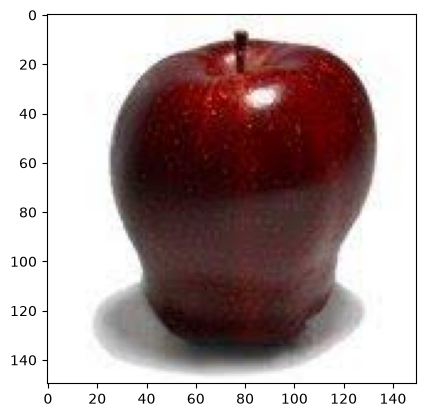

In [21]:
img=Image.open(r'C:\Users\hp\techmindz 2026\Deeplearning\apple_tomato\train\apples\img_p1_40.jpeg')
x=np.array(img.resize((128,128)))

x=x.reshape(-1,128,128,3)
res=model.predict_on_batch(x)
classification=np.argmax(res)
plt.imshow(img)

In [22]:
print(str(res[0][classification]*100)+'% confident that is '+names(classification))

100.0% confident that is apple


In [24]:
#loss='categorical_crossentropy'